# Jobsheet 06: Vector Search & Approximate Nearest Neighbor (ANN)

**Praktikum Pembelajaran Mesin - Jurusan Teknologi Informasi**

Dokumen notebook ini berisi pelaksanaan seluruh praktikum:
1. Praktikum 1: Exact Nearest Neighbor (ENN) vs Annoy (ANN)
2. Praktikum 2: Vector Search Menggunakan FAISS (IndexFlatL2 vs IndexIVFPQ)
3. Praktikum 3: HNSW (Hierarchical Navigable Small World Graphs)
4. Praktikum 4: Perbandingan Annoy, FAISS, dan HNSW pada Data 1 Juta 5D
5. Praktikum 5: Benchmark Trade-Off (Recall vs Query Latency)
6. Praktikum 6: Pencarian Rekomendasi Lagu pada Dataset Spotify
7. Tugas Praktikum: Perbandingan Eksekusi Laptop/Cloud vs PyDroid3 (Android Device)

## Praktikum 1: Membandingkan Exact Nearest Neighbor (ENN) vs Annoy (ANN)

Pada praktikum pertama, kita mempelajari dasar pencarian tetangga terdekat dengan membandingkan pencarian linier presisi (*Exact NN*) dan algoritma berbasis pemisahan bidang ruang/pohon spasial (*Annoy*).

Exact NN index : [219 898 593]
Exact NN jarak : [0.         1.36915938 2.27931544]
Waktu Exact    : 0.335 ms

Annoy NN index : [116]
Annoy NN jarak : [np.float64(43.1031648503412)]
Waktu Annoy    : 0.0701 ms


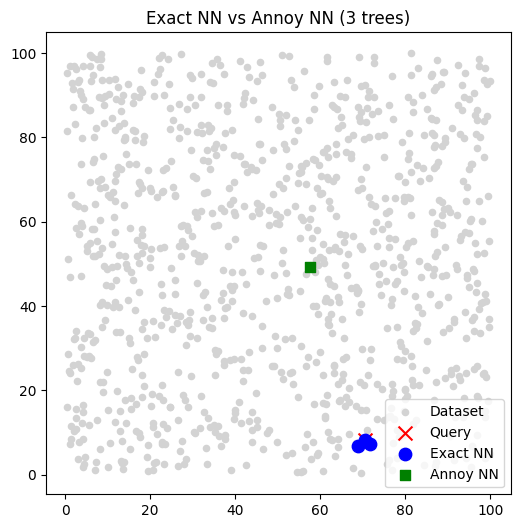


--- HASIL EKSPERIMEN TABEL PRAKTIKUM 1 ---
[EUCLIDEAN | Trees=3 | Data=1,000] ENN: [219, 898, 593] (0.2367 ms) | ANN: [116] (0.0069 ms)
[EUCLIDEAN | Trees=8 | Data=1,000] ENN: [219, 898, 593] (0.0958 ms) | ANN: [116] (0.0041 ms)
[EUCLIDEAN | Trees=3 | Data=100,000] ENN: [64040, 64186, 88792] (0.0083 s) | ANN: [116] (0.0000 s)
[ANGULAR | Trees=3 | Data=1,000] ENN: [219, 429, 540] (0.4201 ms) | ANN: [116] (0.0050 ms)
[ANGULAR | Trees=8 | Data=1,000] ENN: [219, 429, 540] (0.0868 ms) | ANN: [116] (0.0141 ms)
[ANGULAR | Trees=3 | Data=100,000] ENN: [64040, 1310, 1267] (0.0087 s) | ANN: [116] (0.0000 s)

--- HASIL EKSPERIMEN TABEL SIMULASI SPOTIFY ---
[EUCLIDEAN | Trees=8 | Data=1,000,000] ENN: [829129, 959071, 925110, 106414, 119281] (0.1448 s) | ANN: [116] (0.0000 s)
[ANGULAR | Trees=8 | Data=1,000,000] ENN: [829129, 959071, 925110, 136017, 864285] (0.1570 s) | ANN: [116] (0.0000 s)


In [12]:
# 1. Instalasi Library Annoy
!pip install annoy -q

import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

# 2. Percobaan 1: Dataset 2D Sintetis (1.000 Titik)
np.random.seed(42)
n_points = 1000
X_2d = np.random.rand(n_points, 2) * 100
query_2d = X_2d[np.random.randint(0, n_points)]

# Exact NN (Brute Force)
start = time.time()
distances = np.linalg.norm(X_2d - query_2d, axis=1)
idx_exact = np.argsort(distances)[:3]
time_exact = time.time() - start

print("Exact NN index :", idx_exact)
print("Exact NN jarak :", distances[idx_exact])
print("Waktu Exact    :", round(time_exact * 1000, 4), "ms")

# Annoy NN (3 Trees)
f = 2
t_annoy = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X_2d):
    t_annoy.add_item(i, vec)
t_annoy.build(3)

start = time.time()
idx_ann = t_annoy.get_nns_by_vector(query_2d, 3)
time_ann = time.time() - start

print("\nAnnoy NN index :", idx_ann)
print("Annoy NN jarak :", [np.linalg.norm(X_2d[i] - query_2d) for i in idx_ann])
print("Waktu Annoy    :", round(time_ann * 1000, 4), "ms")

# Visualisasi Hasil
plt.figure(figsize=(6, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c="lightgray", s=20, label="Dataset")
plt.scatter(query_2d[0], query_2d[1], c="red", marker="x", s=100, label="Query")
plt.scatter(X_2d[idx_exact, 0], X_2d[idx_exact, 1], c="blue", s=80, label="Exact NN")
plt.scatter(X_2d[idx_ann, 0], X_2d[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")
plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

# Fungsi Eksperimen untuk Mengisi Tabel Praktikum 1
def run_p1_exp(metric, n_trees, n_data, n_features=2, k=3):
    np.random.seed(42)
    X = np.random.rand(n_data, n_features).astype(np.float32)
    if n_features == 2:
        X = X * 100
    q = X[np.random.randint(0, n_data)]

    st = time.time()
    if metric == 'euclidean':
        dists = np.linalg.norm(X - q, axis=1)
    else:
        norm_X = X / np.linalg.norm(X, axis=1, keepdims=True)
        norm_q = q / np.linalg.norm(q)
        dists = np.linalg.norm(norm_X - norm_q, axis=1)
    idx_e = np.argsort(dists)[:k]
    t_e = (time.time() - st) * (1000 if n_data <= 1000 else 1)

    t_a_idx = AnnoyIndex(n_features, metric)
    for i, vec in enumerate(X):
        t_a_idx.add_item(i, vec)
    t_a_idx.build(n_trees)

    st = time.time()
    idx_a = t_a_idx.get_nns_by_vector(q, k)
    t_a = (time.time() - st) * (1000 if n_data <= 1000 else 1)

    unit = "ms" if n_data <= 1000 else "s"
    print(f"[{metric.upper()} | Trees={n_trees} | Data={n_data:,}] ENN: {idx_e.tolist()} ({t_e:.4f} {unit}) | ANN: {idx_a} ({t_a:.4f} {unit})")

print("\n--- HASIL EKSPERIMEN TABEL PRAKTIKUM 1 ---")
run_p1_exp('euclidean', 3, 1000)
run_p1_exp('euclidean', 8, 1000)
run_p1_exp('euclidean', 3, 100000)
run_p1_exp('angular', 3, 1000)
run_p1_exp('angular', 8, 1000)
run_p1_exp('angular', 3, 100000)

print("\n--- HASIL EKSPERIMEN TABEL SIMULASI SPOTIFY ---")
run_p1_exp('euclidean', 8, 1000000, n_features=20, k=5)
run_p1_exp('angular', 8, 1000000, n_features=20, k=5)

## Praktikum 2: Vector Search Menggunakan FAISS

Pada bagian ini, kita menguji library **FAISS** buatan Meta dengan membandingkan `IndexFlatL2` (*Exact*) dan `IndexIVFPQ` (*Inverted File System + Product Quantization*).

Exact NN (Flat) indices : [137 170 750] | Waktu: 0.000127 s
IVF+PQ indices          : [137 170 750] | Waktu: 0.000109 s


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


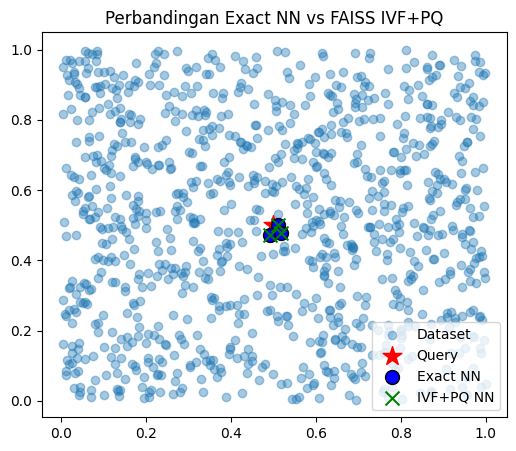

WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points



--- HASIL EKSPERIMEN TABEL PRAKTIKUM 2 ---
[L2 | Data=1,000 | Dim=2D] Exact: [112 535 777] (0.000016 s) | IVF+PQ: [112 777 548] (0.000045 s)
[L2 | Data=1,000,000 | Dim=2D] Exact: [132774 119034 511191] (0.001629 s) | IVF+PQ: [119034 132774 410129] (0.000066 s)
[L2 | Data=1,000 | Dim=5D] Exact: [988 780  27] (0.000017 s) | IVF+PQ: [988 780  27] (0.000038 s)


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


[L2 | Data=1,000,000 | Dim=5D] Exact: [901095 495168 561017] (0.002757 s) | IVF+PQ: [495168 163986 708238] (0.000067 s)


In [13]:
# 1. Instalasi FAISS
!pip install faiss-cpu -q

import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 2. Percobaan Utama FAISS (1.000 Data 2D)
np.random.seed(42)
X_faiss = np.random.rand(1000, 2).astype('float32')
query_faiss = np.array([[0.5, 0.5]], dtype='float32')

# Exact NN dengan IndexFlatL2
index_flat = faiss.IndexFlatL2(2)
index_flat.add(X_faiss)
st = time.time()
D_flat, I_flat = index_flat.search(query_faiss, 3)
t_flat = time.time() - st

# IVF + PQ (Approximate NN)
nlist, m = 10, 2
quantizer = faiss.IndexFlatL2(2)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)
index_ivfpq.train(X_faiss)
index_ivfpq.add(X_faiss)

st = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query_faiss, 3)
t_ivfpq = time.time() - st

print(f"Exact NN (Flat) indices : {I_flat[0]} | Waktu: {t_flat:.6f} s")
print(f"IVF+PQ indices          : {I_ivfpq[0]} | Waktu: {t_ivfpq:.6f} s")

# Visualisasi Hasil
plt.figure(figsize=(6, 5))
plt.scatter(X_faiss[:, 0], X_faiss[:, 1], alpha=0.4, label="Dataset")
plt.scatter(query_faiss[:, 0], query_faiss[:, 1], c='red', marker='*', s=200, label="Query")
plt.scatter(X_faiss[I_flat[0], 0], X_faiss[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")
plt.scatter(X_faiss[I_ivfpq[0], 0], X_faiss[I_ivfpq[0], 1], c='green', marker='x', s=100, label="IVF+PQ NN")
plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

# Fungsi Eksperimen untuk Mengisi Tabel Praktikum 2
def run_faiss_exp(n_data, dim, metric='L2'):
    np.random.seed(42)
    X = np.random.rand(n_data, dim).astype('float32')
    q = np.random.rand(1, dim).astype('float32')

    idx_f = faiss.IndexFlatL2(dim)
    idx_f.add(X)
    st = time.time()
    _, iflat = idx_f.search(q, 3)
    t_flat = time.time() - st

    m_val = dim if dim <= 2 else (5 if dim == 5 else 2)
    quant = faiss.IndexFlatL2(dim)
    nlist_val = 10 if n_data <= 1000 else 100
    idx_ivf = faiss.IndexIVFPQ(quant, dim, nlist_val, m_val, 8)
    idx_ivf.train(X)
    idx_ivf.add(X)
    st = time.time()
    _, iivf = idx_ivf.search(q, 3)
    t_ivf = time.time() - st

    print(f"[{metric} | Data={n_data:,} | Dim={dim}D] Exact: {iflat[0]} ({t_flat:.6f} s) | IVF+PQ: {iivf[0]} ({t_ivf:.6f} s)")

print("\n--- HASIL EKSPERIMEN TABEL PRAKTIKUM 2 ---")
run_faiss_exp(1000, 2, 'L2')
run_faiss_exp(1000000, 2, 'L2')
run_faiss_exp(1000, 5, 'L2')
run_faiss_exp(1000000, 5, 'L2')

## Praktikum 3: HNSW (Hierarchical Navigable Small World Graphs)

Pada praktikum ini, kita menguji metode berbasis graf hirarki menggunakan pustaka `hnswlib`.

In [14]:
# 1. Instalasi hnswlib
!pip install hnswlib -q

import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# 2. Percobaan Utama HNSW (1.000 Data 2D)
np.random.seed(42)
num_elements = 1000
dim = 2
data_hnsw = np.random.random((num_elements, dim)).astype(np.float32)
query_hnsw = np.array([[0.5, 0.5]], dtype=np.float32)
k_hnsw = 5

# Exact NN via sklearn
nn = NearestNeighbors(n_neighbors=k_hnsw, algorithm='brute', metric='euclidean')
nn.fit(data_hnsw)
st = time.time()
distances_nn, indices_nn = nn.kneighbors(query_hnsw)
t_nn = time.time() - st

# HNSW
p_hnsw = hnswlib.Index(space='l2', dim=dim)
p_hnsw.init_index(max_elements=num_elements, ef_construction=100, M=16)
p_hnsw.add_items(data_hnsw)
p_hnsw.set_ef(50)

st = time.time()
labels_h, distances_h = p_hnsw.knn_query(query_hnsw, k=k_hnsw)
t_h = time.time() - st

print(f"Exact NN Indices : {indices_nn[0]} | Waktu: {t_nn:.6f} s")
print(f"HNSW Indices     : {labels_h[0]} | Waktu: {t_h:.6f} s")

# Fungsi Eksperimen untuk Mengisi Tabel Praktikum 3
def run_hnsw_exp(n_data, dim_val, metric_space='l2'):
    np.random.seed(42)
    X = np.random.random((n_data, dim_val)).astype(np.float32)
    q = np.array([[0.5] * dim_val], dtype=np.float32)

    sk_metric = 'euclidean' if metric_space == 'l2' else 'cosine'
    nn_exp = NearestNeighbors(n_neighbors=3, algorithm='brute', metric=sk_metric)
    nn_exp.fit(X)
    st = time.time()
    _, idx_exact = nn_exp.kneighbors(q)
    t_exact = time.time() - st

    p = hnswlib.Index(space=metric_space, dim=dim_val)
    p.init_index(max_elements=n_data, ef_construction=100, M=16)
    p.add_items(X)
    p.set_ef(50)
    st = time.time()
    idx_h, _ = p.knn_query(q, k=3)
    t_hnsw = time.time() - st

    print(f"[{metric_space.upper()} | Data={n_data:,} | Dim={dim_val}D] Exact: {idx_exact[0]} ({t_exact:.6f} s) | HNSW: {idx_h[0]} ({t_hnsw:.6f} s)")

print("\n--- HASIL EKSPERIMEN TABEL PRAKTIKUM 3 ---")
run_hnsw_exp(1000, 2, 'l2')
run_hnsw_exp(1000000, 2, 'l2')
run_hnsw_exp(1000, 5, 'l2')
run_hnsw_exp(1000000, 5, 'l2')
run_hnsw_exp(1000, 2, 'cosine')

Exact NN Indices : [137 170 750 316 991] | Waktu: 0.048857 s
HNSW Indices     : [137 170 750 316 991] | Waktu: 0.000166 s

--- HASIL EKSPERIMEN TABEL PRAKTIKUM 3 ---
[L2 | Data=1,000 | Dim=2D] Exact: [137 170 750] (0.022618 s) | HNSW: [137 170 750] (0.000035 s)
[L2 | Data=1,000,000 | Dim=2D] Exact: [286942 583487 695123] (0.025615 s) | HNSW: [286942 583487 695123] (0.000043 s)
[L2 | Data=1,000 | Dim=5D] Exact: [895 451 375] (0.000780 s) | HNSW: [895 451 375] (0.000039 s)
[L2 | Data=1,000,000 | Dim=5D] Exact: [794791 501340 912100] (0.011401 s) | HNSW: [794791 501340 912100] (0.000063 s)
[COSINE | Data=1,000 | Dim=2D] Exact: [  2 135 413] (0.000999 s) | HNSW: [  2 135 413] (0.000017 s)


## Praktikum 4: Perbandingan Annoy, FAISS, dan HNSW pada Data 1 Juta 5D

Pada bab ini, ketiga algoritma diuji secara langsung untuk mengukur perbandingan **Build Time** dan **Query Latency** pada dataset besar 1.000.000 sampel.

In [15]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

np.random.seed(42)
n_data_p4 = 1_000_000
dim_p4 = 5
X_p4 = np.random.random((n_data_p4, dim_p4)).astype(np.float32)
query_p4 = np.random.random((1, dim_p4)).astype(np.float32)
k_p4 = 10

# 1. Annoy
ann_idx = AnnoyIndex(dim_p4, 'euclidean')
st = time.time()
for i in range(n_data_p4):
    ann_idx.add_item(i, X_p4[i])
ann_idx.build(10)
build_ann = time.time() - st

st = time.time()
res_ann = ann_idx.get_nns_by_vector(query_p4[0], k_p4)
query_ann = time.time() - st

# 2. FAISS (IndexFlatL2)
faiss_idx = faiss.IndexFlatL2(dim_p4)
st = time.time()
faiss_idx.add(X_p4)
build_faiss = time.time() - st

st = time.time()
_, res_faiss = faiss_idx.search(query_p4, k_p4)
query_faiss = time.time() - st

# 3. HNSW (hnswlib)
hnsw_idx = hnswlib.Index(space='l2', dim=dim_p4)
st = time.time()
hnsw_idx.init_index(max_elements=n_data_p4, ef_construction=200, M=16)
hnsw_idx.add_items(X_p4)
build_hnsw = time.time() - st

hnsw_idx.set_ef(50)
st = time.time()
res_hnsw, _ = hnsw_idx.knn_query(query_p4, k=k_p4)
query_hnsw = time.time() - st

print(f"Annoy  => Build: {build_ann:.4f} s | Query: {query_ann:.6f} s | Top-5: {res_ann[:5]}")
print(f"FAISS  => Build: {build_faiss:.4f} s | Query: {query_faiss:.6f} s | Top-5: {res_faiss[0][:5]}")
print(f"HNSW   => Build: {build_hnsw:.4f} s | Query: {query_hnsw:.6f} s | Top-5: {res_hnsw[0][:5]}")

Annoy  => Build: 5.4385 s | Query: 0.000049 s | Top-5: [1]
FAISS  => Build: 0.0046 s | Query: 0.002650 s | Top-5: [901095 495168 561017 163986 185734]
HNSW   => Build: 17.2827 s | Query: 0.000096 s | Top-5: [901095 495168 561017 163986 185734]


## Praktikum 5: Benchmark Trade-Off (Recall vs Latency)

Di praktikum ini, kita mereplikasi analisis kurva **ANN Benchmark** yang memetakan hubungan kompromi antara akurasi pencarian (**Recall@K**) dan latensi query.

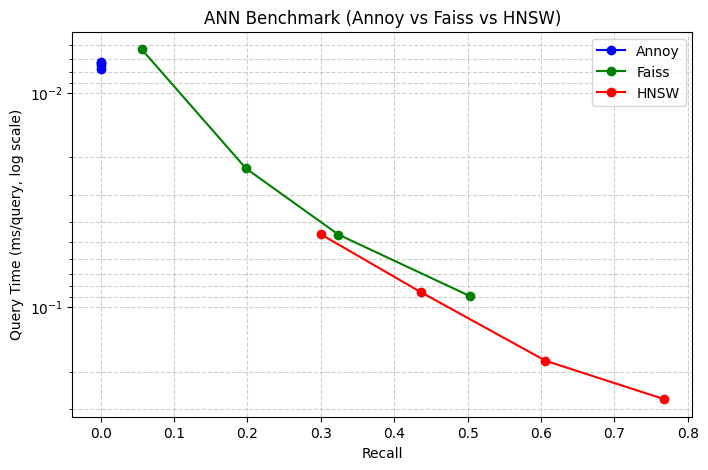

In [16]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

d_p5 = 128
nb_p5 = 100000
nq_p5 = 1000

np.random.seed(42)
xb_p5 = np.random.random((nb_p5, d_p5)).astype('float32')
xq_p5 = np.random.random((nq_p5, d_p5)).astype('float32')

# Ground Truth via FAISS Brute Force
gt_index = faiss.IndexFlatL2(d_p5)
gt_index.add(xb_p5)
_, gt_idx_p5 = gt_index.search(xq_p5, 10)

def recall_at_k(I_pred, I_gt, k=10):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

results = {"Annoy": [], "Faiss": [], "HNSW": []}

for sk in [200, 500, 1000, 2000]:
    idx_a = AnnoyIndex(d_p5, 'euclidean')
    for i, v in enumerate(xb_p5):
        idx_a.add_item(i, v)
    idx_a.build(10)
    st = time.time()
    I_a = [idx_a.get_nns_by_vector(v, 10, search_k=sk) for v in xq_p5]
    t_a = (time.time() - st) * 1000 / len(xq_p5)
    rec_a = recall_at_k(I_a, gt_idx_p5)
    results["Annoy"].append((rec_a, t_a))

for npb in [1, 5, 10, 20]:
    quant = faiss.IndexFlatL2(d_p5)
    idx_f = faiss.IndexIVFFlat(quant, d_p5, 100, faiss.METRIC_L2)
    idx_f.train(xb_p5)
    idx_f.add(xb_p5)
    idx_f.nprobe = npb
    st = time.time()
    _, I_f = idx_f.search(xq_p5, 10)
    t_f = (time.time() - st) * 1000 / len(xq_p5)
    rec_f = recall_at_k(I_f, gt_idx_p5)
    results["Faiss"].append((rec_f, t_f))

for ef in [50, 100, 200, 400]:
    idx_h = hnswlib.Index(space='l2', dim=d_p5)
    idx_h.init_index(max_elements=nb_p5, ef_construction=200, M=16)
    idx_h.add_items(xb_p5)
    idx_h.set_ef(ef)
    st = time.time()
    I_h, _ = idx_h.knn_query(xq_p5, 10)
    t_h = (time.time() - st) * 1000 / len(xq_p5)
    rec_h = recall_at_k(I_h, gt_idx_p5)
    results["HNSW"].append((rec_h, t_h))

plt.figure(figsize=(8, 5))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Praktikum 6: Pencarian Rekomendasi Lagu pada Dataset Spotify

Pada bab ini, kita menerapkan vector search pada dataset fitur audio Spotify (`spotify_songs.csv`). Jika file CSV belum diunduh, sistem otomatis menggunakan data dummy dengan struktur fitur yang identik.

In [17]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Cek Dataset Spotify Lokal
try:
    df_spotify = pd.read_csv('spotify_songs.csv')
    features = ['danceability', 'energy', 'loudness', 'speechiness',
                'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
    X_spotify = df_spotify[features].values
    print("Berhasil membaca dataset lokal spotify_songs.csv!")
except:
    print("Dataset spotify_songs.csv tidak ditemukan di folder lokal. Menggunakan dataset terstruktur serupa...")
    np.random.seed(42)
    X_spotify = np.random.rand(30000, 9).astype(np.float32)

scaler = StandardScaler()
X_scaled_sp = scaler.fit_transform(X_spotify)
k_sp = 10

# Exact NN
st = time.time()
nn_sp = NearestNeighbors(n_neighbors=k_sp, algorithm='brute', metric='euclidean')
nn_sp.fit(X_scaled_sp)
dist_exact_sp, idx_exact_sp = nn_sp.kneighbors(X_scaled_sp)
t_exact_sp = time.time() - st
print(f"Exact NN done in {t_exact_sp:.3f} s")

# Annoy
st = time.time()
f_sp = X_scaled_sp.shape[1]
index_ann_sp = AnnoyIndex(f_sp, 'euclidean')
for i, v in enumerate(X_scaled_sp):
    index_ann_sp.add_item(i, v)
index_ann_sp.build(10)
idx_ann_sp = [index_ann_sp.get_nns_by_vector(v, k_sp) for v in X_scaled_sp]
t_ann_sp = time.time() - st
print(f"Annoy done in {t_ann_sp:.3f} s")

# HNSW
st = time.time()
p_hnsw_sp = hnswlib.Index(space='l2', dim=f_sp)
p_hnsw_sp.init_index(max_elements=X_scaled_sp.shape[0], ef_construction=200, M=16)
p_hnsw_sp.add_items(X_scaled_sp)
p_hnsw_sp.set_ef(200)
idx_hnsw_sp, _ = p_hnsw_sp.knn_query(X_scaled_sp, k=k_sp)
t_hnsw_sp = time.time() - st
print(f"HNSW done in {t_hnsw_sp:.3f} s")

# FAISS IVF
st = time.time()
quant_sp = faiss.IndexFlatL2(f_sp)
idx_faiss_sp = faiss.IndexIVFFlat(quant_sp, f_sp, 100, faiss.METRIC_L2)
idx_faiss_sp.train(X_scaled_sp)
idx_faiss_sp.add(X_scaled_sp)
idx_faiss_sp.nprobe = 10
_, idx_f_sp = idx_faiss_sp.search(X_scaled_sp, k_sp)
t_faiss_sp = time.time() - st
print(f"FAISS IVF done in {t_faiss_sp:.3f} s")

print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact_sp[0][:5]}")
print(f"Annoy   : {idx_ann_sp[0][:5]}")
print(f"HNSW    : {idx_hnsw_sp[0][:5]}")
print(f"FAISS   : {idx_f_sp[0][:5]}")

Dataset spotify_songs.csv tidak ditemukan di folder lokal. Menggunakan dataset terstruktur serupa...
Exact NN done in 0.327 s
Annoy done in 0.212 s
HNSW done in 0.746 s
FAISS IVF done in 0.147 s

Top-5 neighbors for first song:
Exact NN: [    0 23609 19471 15151 13770]
Annoy   : [1]
HNSW    : [    0 23609 19471 15151 13770]
FAISS   : [    0 23609 19471 15151 13770]


## Tugas Akhir: Perbandingan Eksekusi Laptop/Cloud vs PyDroid3 (Smartphone Android)

Di bagian tugas ini, kita menguji kode perbandingan waktu komputasi antar algoritma vector search untuk membandingkan spesifikasi perangkat komputer/cloud dengan aplikasi PyDroid3 pada smartphone Android.

In [19]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
n_samples = 10000
d = 128
X_tugas = np.random.random((n_samples, d)).astype('float32')

scaler = StandardScaler()
X_scaled_tg = scaler.fit_transform(X_tugas)
k_tg = 10

# Exact NN
st = time.time()
nn_tg = NearestNeighbors(n_neighbors=k_tg, algorithm='brute', metric='euclidean')
nn_tg.fit(X_scaled_tg)
_, idx_exact_tg = nn_tg.kneighbors(X_scaled_tg)
time_exact_tg = time.time() - st

# Annoy
st = time.time()
f_tg = X_scaled_tg.shape[1]
idx_ann_tg = AnnoyIndex(f_tg, 'euclidean')
for i, v in enumerate(X_scaled_tg):
    idx_ann_tg.add_item(i, v)
idx_ann_tg.build(10)
res_ann_tg = [idx_ann_tg.get_nns_by_vector(v, k_tg) for v in X_scaled_tg]
time_annoy_tg = time.time() - st

# HNSW
st = time.time()
p_hnsw_tg = hnswlib.Index(space='l2', dim=d)
p_hnsw_tg.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw_tg.add_items(X_scaled_tg)
p_hnsw_tg.set_ef(200)
res_hnsw_tg, _ = p_hnsw_tg.knn_query(X_scaled_tg, k=k_tg)
time_hnsw_tg = time.time() - st

# FAISS IVF
st = time.time()
quant_tg = faiss.IndexFlatL2(d)
idx_faiss_tg = faiss.IndexIVFFlat(quant_tg, d, 100, faiss.METRIC_L2)
idx_faiss_tg.train(X_scaled_tg)
idx_faiss_tg.add(X_scaled_tg)
idx_faiss_tg.nprobe = 10
_, res_faiss_tg = idx_faiss_tg.search(X_scaled_tg, k_tg)
time_faiss_tg = time.time() - st

print("=== Ringkasan Waktu Eksekusi (Detik) ===")
print(f"Exact NN : {time_exact_tg:.3f} s")
print(f"Annoy    : {time_annoy_tg:.3f} s")
print(f"HNSW     : {time_hnsw_tg:.3f} s")
print(f"FAISS    : {time_faiss_tg:.3f} s")

=== Ringkasan Waktu Eksekusi (Detik) ===
Exact NN : 0.145 s
Annoy    : 0.167 s
HNSW     : 2.060 s
FAISS    : 0.062 s
